In [2]:
%pylab inline

nzs=4
import gc
import glob
import fitsio
import numpy as np
import numpy.lib.recfunctions as rfn
import matplotlib.cm as cm
fieldname='XMM'

Populating the interactive namespace from numpy and matplotlib


In [ ]:
cd /lustre/work/xiangchong.li/work/galSim-HSC/s19/s19-1/anaCat_newS19Mask_fdeltacut/

/lustre/work/xiangchong.li/work/galSim-HSC/s19/s19-1/anaCat_newS19Mask_fdeltacut


In [2]:
def main(pzname):
    pzDir=os.path.join('catalog_tracts','XMM_tracts')
    pbins= pyfits.getdata(os.path.join(pzDir,'8522_pz_pdf_%s.fits' %pzname),ext=2)['BINS']
    inDir  =   os.path.join('catalog_tracts','%s_tracts' %fieldname) 
    fnames=glob.glob(os.path.join(inDir,'*_pz_pdf_%s.fits' %(pzname)))
    
    pTest=[]
    for pfname in fnames[:5]:
        pata=pyfits.getdata(pfname)
        fname=pfname.split('pz_pdf')[0]+'pz.fits'
        data=pyfits.getdata(fname)
        poz_best=data['dnnz_photoz_best']# fix the best-fit estimation code for binning
        del data,fname
        fname=pfname.split('pz_pdf')[0]+'no_m.fits'
        iz=0
        zmin=   (iz+1)*0.3
        zmax=   (iz+2)*0.3
        tmp_msk=(poz_best>zmin)&(poz_best<=zmax)
        pTest.append(pata[tmp_msk]['PDF'])
        del tmp_msk,pata
        gc.collect()
    plt.close()
    pTest=np.vstack(pTest)
    out=np.log10(np.sum(pTest[:,pbins>2.],axis=1)/np.sum(pTest,axis=1))
    _=plt.hist(out,bins=40,range=(-8,0),density=True,label=pzname)
    plt.xlabel('log10(P(>2))')
    plt.legend()
    return pbins,pTest,out

/lustre/work/xiangchong.li/ana/lsst_stack/conda/miniconda3-py37_4.8.2/envs/lsst-scipipe-cb4e2dc/lib/python3.7/site-packages/ipykernel_launcher.py:24: RuntimeWarning: divide by zero encountered in log10


0.9463037735699383

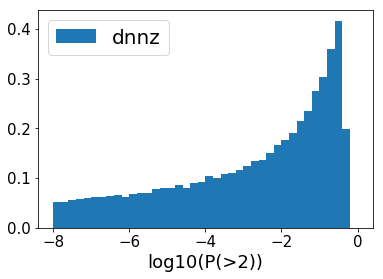

In [4]:
#pzname='mizuki'
#pzname='dempz'

pb1,pTest1,out1=main('dnnz')
np.sum(out1<-0.5)/len(out1)

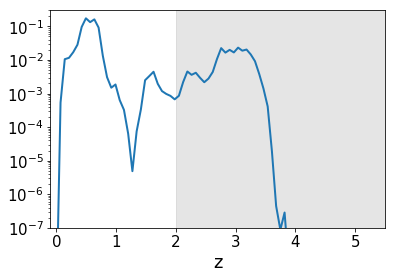

In [64]:
plt.plot(pb1,pTest1[1])
plt.yscale('log')
plt.ylim(1e-7,3e-1)
plt.xlim(-0.1,5.5)
plt.xlabel('z')
plt.axvspan(2,10,alpha=0.2, color='grey')

remove 5.37 percent galaxy 
with DNNZ P(>2) < 0.3162


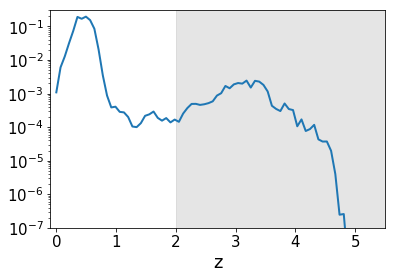

In [88]:
thres=-.5
plt.plot(pb1,np.average(pTest1[out1<thres],axis=0))
plt.yscale('log')
plt.ylim(1e-7,3e-1)
plt.xlim(-0.1,5.5)
plt.xlabel('z')
plt.axvspan(2,10,alpha=0.2, color='grey')
print('remove %.2f percent galaxy ' %(100-np.sum(out1<thres)/len(out1)*100.))
print('with DNNZ P(>2) < %.4f' %(10**(thres)))

/lustre/work/xiangchong.li/ana/lsst_stack/conda/miniconda3-py37_4.8.2/envs/lsst-scipipe-cb4e2dc/lib/python3.7/site-packages/ipykernel_launcher.py:24: RuntimeWarning: divide by zero encountered in log10


0.9571215024529229

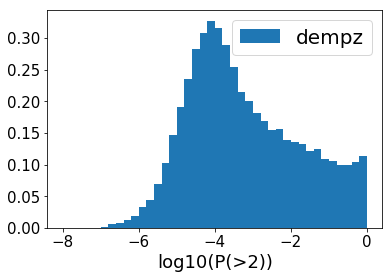

In [5]:
pb2,pTest2,out2=main('dempz')
np.sum(out2<-0.5)/len(out2)

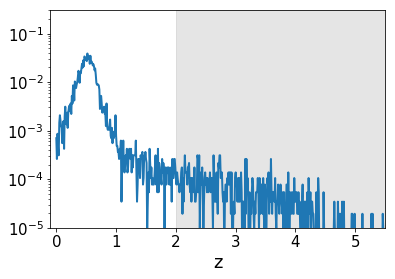

In [62]:
plt.plot(pb2,pTest2[1])
plt.yscale('log')
plt.ylim(1e-5,3e-1)
plt.xlim(-0.1,5.5)
plt.xlabel('z')
plt.axvspan(2,10,alpha=0.2, color='grey')

remove 0.00 percent galaxies
with DEMPZ P(>2) < 1.0000


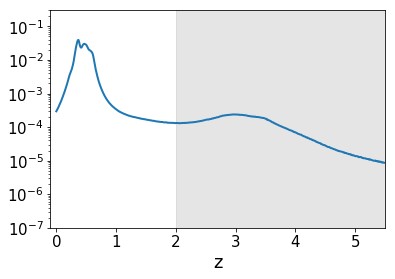

In [84]:
thres=-0.
plt.plot(pb2,np.average(pTest2[out2<thres],axis=0))
plt.yscale('log')
plt.ylim(1e-7,3e-1)
plt.xlim(-0.1,5.5)
plt.xlabel('z')
plt.axvspan(2,10,alpha=0.2, color='grey')
print('remove %.2f percent galaxies' %(100-np.sum(out2<thres)/len(out2)*100.))
print('with DEMPZ P(>2) < %.4f' %(10**(thres)))

/lustre/work/xiangchong.li/ana/lsst_stack/conda/miniconda3-py37_4.8.2/envs/lsst-scipipe-cb4e2dc/lib/python3.7/site-packages/ipykernel_launcher.py:24: RuntimeWarning: divide by zero encountered in log10


0.9465068922305765

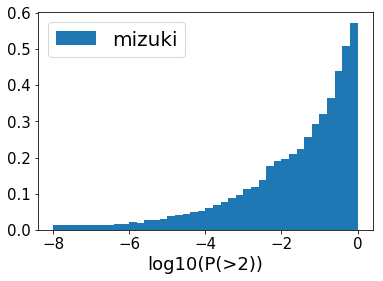

In [10]:
pb3,pTest3,out3=main('mizuki')
np.sum(out3<-0.2)/len(out3)

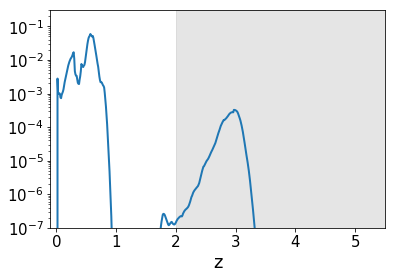

In [60]:
plt.plot(pb3,pTest3[1])
plt.yscale('log')
plt.ylim(1e-7,3e-1)
plt.xlim(-0.1,5.5)
plt.xlabel('z')
plt.axvspan(2,10,alpha=0.2, color='grey')

remove 12.26 percent galaxies
with MIZUKIZ P(>2) < 0.3162


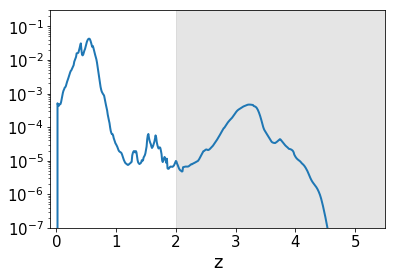

In [81]:
thres=-0.5
plt.plot(pb3,np.average(pTest3[out3<thres],axis=0))
plt.yscale('log')
plt.ylim(1e-7,3e-1)
plt.xlim(-0.1,5.5)
plt.axvspan(2,10,alpha=0.2, color='grey')
plt.xlabel('z')
print('remove %.2f percent galaxies' %(100-np.sum(out3<thres)/len(out3)*100.))
print('with MIZUKIZ P(>2) < %.4f' %(10**(thres)))